
# OLS 与 IV 模拟

本 Notebook 包含两个主实验：

1. OLS 的无偏性与一致性；
2. IV 中内生性强度与工具变量强度如何影响有限样本表现。

参数均为教学用模拟设定。


[返回理论正文](../../lectures/monte-carlo.qmd#sec-mc-econometrics) · [下载 Notebook (ZIP)](../../resources/monte-carlo/downloads/01-ols-iv-simulation.zip)

本 Notebook 已从头执行并保存输出；网页渲染不执行代码。

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.sandbox.regression.gmm import IV2SLS

SEED = 20261001



## Part A：OLS 的无偏性


In [2]:

def ols_mc(n=100, B=5000, beta0=1.0, beta1=2.0, seed=SEED):
    rng = np.random.default_rng(seed)
    bhat = np.empty(B)

    for b in range(B):
        x = rng.normal(0, 1, n)
        u = rng.normal(0, 1, n)
        y = beta0 + beta1 * x + u

        X = sm.add_constant(x)
        fit = sm.OLS(y, X).fit()
        bhat[b] = fit.params[1]

    return bhat

bhat_100 = ols_mc(n=100, B=5000)
pd.Series({
    "true_beta": 2.0,
    "mean_beta_hat": bhat_100.mean(),
    "bias": bhat_100.mean() - 2.0,
    "empirical_sd": bhat_100.std(ddof=1),
})


true_beta        2.000000
mean_beta_hat    2.001526
bias             0.001526
empirical_sd     0.102839
dtype: float64

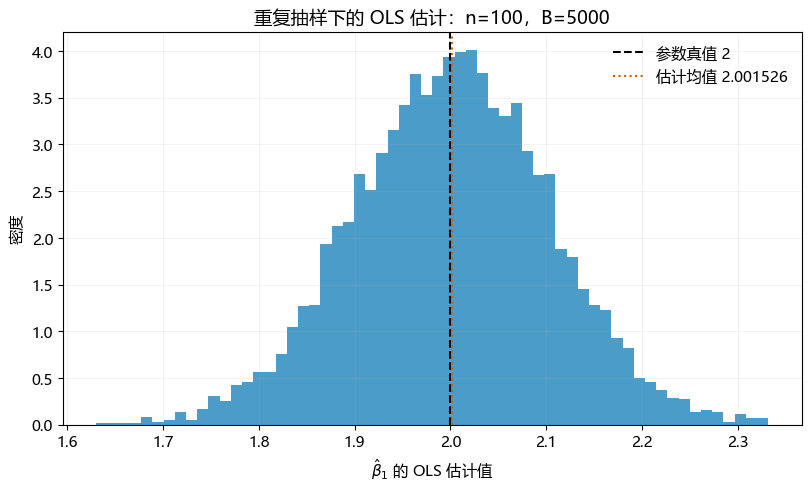

In [3]:
plt.rcParams.update({
    'font.family': 'Microsoft YaHei', 'font.size': 11,
    'axes.unicode_minus': False,
})
colors = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#666666']
line_styles = ['-', '--', '-.', ':', (0, (5, 1, 1, 1))]

# 无偏性：完整直方图与估计均值，不将单次估计等同于期望。
fig, axis = plt.subplots(figsize=(8, 4.8), layout='constrained')
axis.hist(bhat_100, bins=60, density=True, color=colors[0], alpha=.7)
axis.axvline(2, color='black', linestyle='--', label='参数真值 2')
axis.axvline(bhat_100.mean(), color=colors[1], linestyle=':',
             label=f'估计均值 {bhat_100.mean():.6f}')
axis.set(xlabel=r'$\hat{\beta}_{1}$ 的 OLS 估计值', ylabel='密度',
         title='重复抽样下的 OLS 估计：n=100，B=5000')
axis.legend(frameon=False)
axis.grid(alpha=.15)
plt.show()


## OLS 的一致性


In [4]:

sample_sizes = [20, 50, 100, 500, 2000]
ols_results = {}

for n in sample_sizes:
    vals = ols_mc(n=n, B=3000, seed=SEED + n)
    ols_results[n] = vals

ols_summary = pd.DataFrame([
    {
        "n": n,
        "mean_beta_hat": vals.mean(),
        "bias": vals.mean() - 2.0,
        "empirical_sd": vals.std(ddof=1),
    }
    for n, vals in ols_results.items()
])

ols_summary


,n,mean_beta_hat,bias,empirical_sd
0,20,2.003953,0.003953,0.243743
1,50,2.001501,0.001501,0.142871
2,100,1.997104,-0.002896,0.100925
3,500,2.000313,0.000313,0.044825
4,2000,1.999967,-0.000033,0.022945


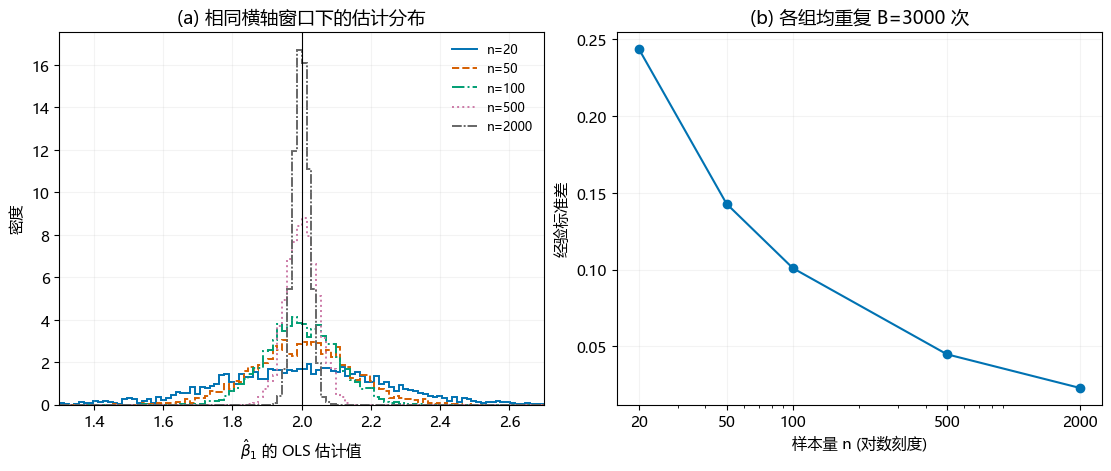

In [5]:
# 一致性：共享显示窗口，密度以全部 B 次结果为分母，不重新归一化截尾样本。
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout='constrained')
edges = np.linspace(1.3, 2.7, 101)
for index, sample_size in enumerate(sample_sizes):
    estimates = ols_results[sample_size]
    counts, edges = np.histogram(estimates, bins=edges)
    axes[0].stairs(counts / len(estimates) / np.diff(edges), edges,
                   label=f'n={sample_size}', color=colors[index],
                   linestyle=line_styles[index], linewidth=1.4)
axes[0].axvline(2, color='black', linewidth=.8)
axes[0].set(xlabel=r'$\hat{\beta}_{1}$ 的 OLS 估计值', ylabel='密度', xlim=(1.3, 2.7),
            title='(a) 相同横轴窗口下的估计分布')
axes[0].legend(frameon=False, fontsize=9)
axes[1].plot(ols_summary['n'], ols_summary['empirical_sd'],
             marker='o', color=colors[0], label='经验标准差')
axes[1].set(xscale='log', xlabel='样本量 n (对数刻度)', ylabel='经验标准差',
            title='(b) 各组均重复 B=3000 次')
axes[1].set_xticks(sample_sizes, [str(value) for value in sample_sizes])
for axis in axes:
    axis.grid(alpha=.15)
plt.show()


## Part B：IV、内生性与弱工具变量

结构模型：

$$
Y_i=\beta X_i+\gamma W_i+u_i.
$$

内生解释变量：

$$
X_i=\pi Z_i+\delta u_i+v_i.
$$

其中：

- $\delta$ 控制内生性强度；
- $\pi$ 控制工具变量强度；
- $Z_i$ 在基础实验中保持外生。


In [6]:

def iv_mc(
    n=500,
    B=1200,
    beta=1.0,
    gamma=1.0,
    pi=1.0,
    delta=0.5,
    seed=SEED
):
    rng = np.random.default_rng(seed)
    ols_hat = np.empty(B)
    iv_hat = np.empty(B)

    for b in range(B):
        z = rng.normal(0, 1, n)
        w = rng.normal(0, 1, n)
        u = rng.normal(0, 1, n)
        v = rng.normal(0, 1, n)

        x = pi * z + delta * u + v
        y = beta * x + gamma * w + u

        X_ols = sm.add_constant(np.column_stack([x, w]))
        ols = sm.OLS(y, X_ols).fit()
        ols_hat[b] = ols.params[1]

        # IV2SLS: regressors = [const, x, w], instruments = [const, z, w]
        X_iv = sm.add_constant(np.column_stack([x, w]))
        Z_iv = sm.add_constant(np.column_stack([z, w]))
        iv = IV2SLS(y, X_iv, instrument=Z_iv).fit()
        iv_hat[b] = iv.params[1]

    return pd.DataFrame({"OLS": ols_hat, "IV": iv_hat})



### Experiment B1：固定较强工具变量，逐步增强内生性


In [7]:

delta_grid = [0.0, 0.2, 0.5, 0.8]
endogeneity_results = {}

for d in delta_grid:
    endogeneity_results[d] = iv_mc(
        n=500, B=1200, pi=1.0, delta=d, seed=SEED + int(d * 1000)
    )

summary_b1 = []
for d, df in endogeneity_results.items():
    for method in ["OLS", "IV"]:
        vals = df[method].to_numpy()
        summary_b1.append({
            "delta": d,
            "method": method,
            "mean": vals.mean(),
            "bias": vals.mean() - 1.0,
            "sd": vals.std(ddof=1),
            "rmse": np.sqrt(np.mean((vals - 1.0)**2)),
        })
pd.DataFrame(summary_b1)


,delta,method,mean,bias,sd,rmse
0,0.0,OLS,0.999194,-0.000806,0.031887,0.031884
1,0.0,IV,0.999176,-0.000824,0.045696,0.045684
2,0.2,OLS,1.098756,0.098756,0.030988,0.103500
3,0.2,IV,1.001215,0.001215,0.044697,0.044695
4,0.5,OLS,1.222924,0.222924,0.027821,0.224652
5,0.5,IV,0.998593,-0.001407,0.044248,0.044251
6,0.8,OLS,1.302554,0.302554,0.023513,0.303465
7,0.8,IV,0.997258,-0.002742,0.044214,0.044281


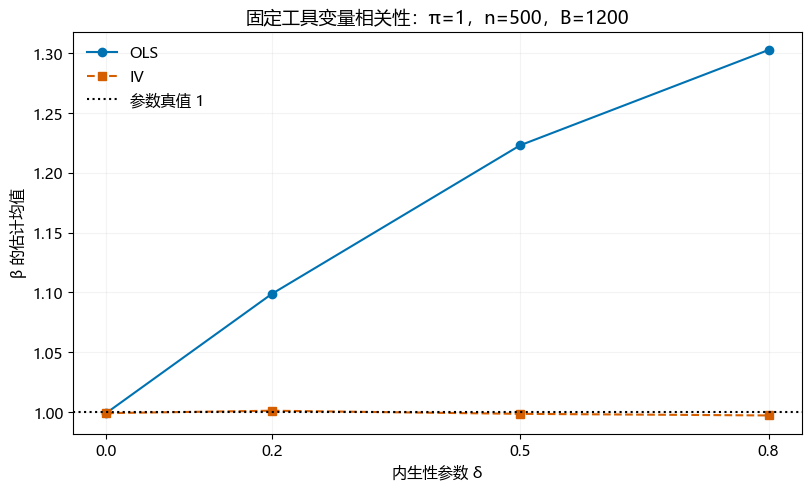

In [8]:
# 内生性：比较同样本 OLS/IV 的估计均值，不添加未经解释的总体置信区间。
fig, axis = plt.subplots(figsize=(8, 4.8), layout='constrained')
for method, color, marker, style in [('OLS', colors[0], 'o', '-'),
                                      ('IV', colors[1], 's', '--')]:
    means = [endogeneity_results[value][method].mean() for value in delta_grid]
    axis.plot(delta_grid, means, color=color, marker=marker,
               linestyle=style, label=method)
axis.axhline(1, color='black', linestyle=':', label='参数真值 1')
axis.set(xlabel='内生性参数 δ', ylabel='β 的估计均值',
         title='固定工具变量相关性：π=1，n=500，B=1200')
axis.set_xticks(delta_grid)
axis.legend(frameon=False)
axis.grid(alpha=.15)
plt.show()


### Experiment B2：固定内生性，逐步削弱工具变量


In [9]:

pi_grid = [1.0, 0.5, 0.2, 0.05]
weak_results = {}

for pival in pi_grid:
    weak_results[pival] = iv_mc(
        n=500, B=1200, pi=pival, delta=0.5,
        seed=SEED + int(pival * 10000)
    )

summary_b2 = []
for pival, df in weak_results.items():
    vals = df["IV"].to_numpy()
    summary_b2.append({
        "pi": pival,
        "mean_iv": vals.mean(),
        "bias_iv": vals.mean() - 1.0,
        "sd_iv": vals.std(ddof=1),
        "rmse_iv": np.sqrt(np.mean((vals - 1.0)**2)),
        "q01": np.quantile(vals, 0.01),
        "q99": np.quantile(vals, 0.99),
    })

pd.DataFrame(summary_b2)


,pi,mean_iv,bias_iv,sd_iv,rmse_iv,q01,q99
0,1.00,0.998715,-0.001285,0.045591,0.045591,0.886583,1.100663
1,0.50,0.994641,-0.005359,0.092376,0.092493,0.743024,1.187771
2,0.20,0.959567,-0.040433,0.282594,0.285355,0.133405,1.475303
3,0.05,2.122997,1.122997,27.981702,27.992576,-13.636707,23.415511


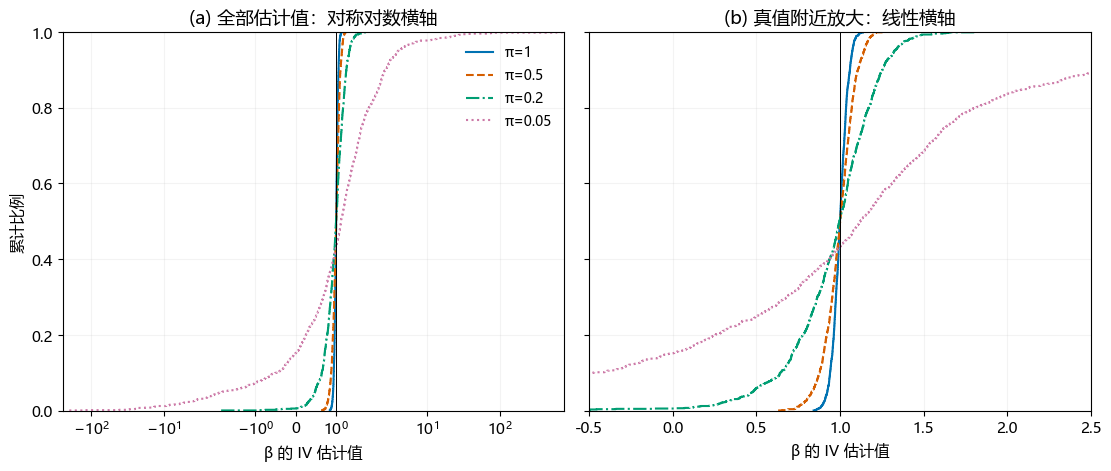

In [10]:
# 弱工具变量：经验分布的分母始终为全部 1200 次，左图保留全部极端值。
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True, layout='constrained')
for index, instrument_strength in enumerate(pi_grid):
    estimates = np.sort(weak_results[instrument_strength]['IV'].to_numpy())
    probabilities = np.arange(1, len(estimates) + 1) / len(estimates)
    for axis in axes:
        axis.step(estimates, probabilities, where='post', color=colors[index],
                   linestyle=line_styles[index], linewidth=1.5,
                   label=f'π={instrument_strength:g}')
for axis in axes:
    axis.axvline(1, color='black', linewidth=.7)
    axis.set(xlabel='β 的 IV 估计值', ylim=(0, 1))
    axis.grid(alpha=.15)
axes[0].set_xscale('symlog', linthresh=2)
axes[0].set(title='(a) 全部估计值：对称对数横轴', ylabel='累计比例')
axes[1].set(title='(b) 真值附近放大：线性横轴', xlim=(-.5, 2.5))
axes[0].legend(frameon=False, fontsize=10)
plt.show()

> 左图显示全部 IV 估计值，横轴采用对称对数刻度。右图仅放大真值附近，累计比例仍按全部 1200 次估计计算，未删除或缩尾处理极端值。


### Experiment B3：内生性强度 × 工具变量强度


In [11]:

delta_grid2 = [0.0, 0.2, 0.4, 0.6, 0.8]
pi_grid2 = [0.05, 0.1, 0.2, 0.5, 1.0]

records = []
for d in delta_grid2:
    for pival in pi_grid2:
        df = iv_mc(
            n=400,
            B=500,
            pi=pival,
            delta=d,
            seed=SEED + int(d * 1000) + int(pival * 10000),
        )
        for method in ["OLS", "IV"]:
            vals = df[method].to_numpy()
            records.append({
                "delta": d,
                "pi": pival,
                "method": method,
                "rmse": np.sqrt(np.mean((vals - 1.0)**2)),
                "bias": vals.mean() - 1.0,
            })

grid_results = pd.DataFrame(records)
grid_results.head()


,delta,pi,method,rmse,bias
0,0.0,0.05,OLS,0.049591,0.001941
1,0.0,0.05,IV,18.654785,-0.871015
2,0.0,0.10,OLS,0.051470,-0.001767
3,0.0,0.10,IV,2.240261,0.125221
4,0.0,0.20,OLS,0.047492,0.000230


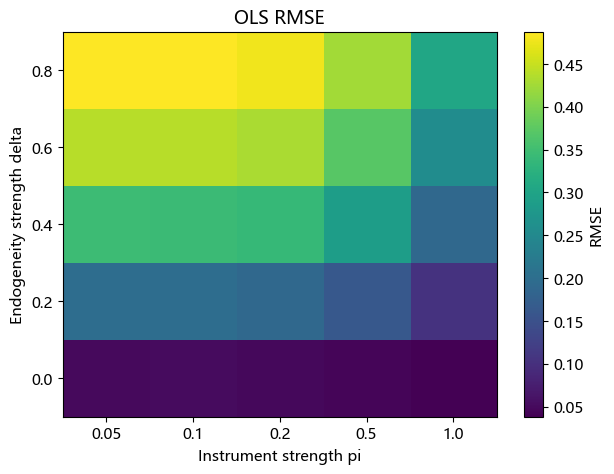

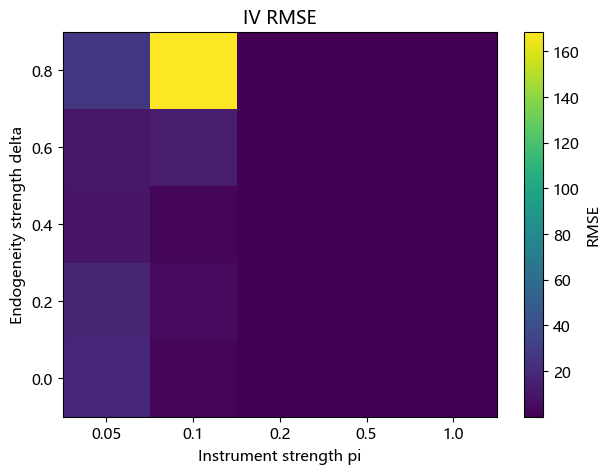

In [12]:

for method in ["OLS", "IV"]:
    pivot = (
        grid_results[grid_results["method"] == method]
        .pivot(index="delta", columns="pi", values="rmse")
        .sort_index(ascending=True)
    )

    fig, ax = plt.subplots(figsize=(7, 5))
    im = ax.imshow(pivot.values, aspect="auto", origin="lower")
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels([str(x) for x in pivot.columns])
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels([str(x) for x in pivot.index])
    ax.set_xlabel("Instrument strength pi")
    ax.set_ylabel("Endogeneity strength delta")
    ax.set_title(f"{method} RMSE")
    fig.colorbar(im, ax=ax, label="RMSE")
    plt.show()



## 诊断与教学结论

这个 Notebook 应至少检查：

1. 当 $\delta=0$ 时，OLS 不应出现系统性偏误；
2. 当 $\delta$ 增大时，OLS 偏误应明显增加；
3. 当 $Z$ 外生且 $\pi$ 较强时，IV 应围绕真实参数；
4. 当 $\pi$ 很小时，IV 的有限样本分布应明显变宽，并可能出现极端估计；
5. 弱工具下的极端估计不能因为“图不好看”而被静默删除。

主结论不是“IV 比 OLS 好”，而是：

- OLS 的可靠性依赖外生性；
- IV 的可靠性依赖工具变量的外生性与相关性；
- 一致性并不保证有限样本表现良好。


## 数值核对与完整估计结果导出

逐次估计数组保留极端值，供正文代码、分位数、图形与已有输出核对。导出位置可由本轮运行器指定，独立运行默认放入 output/monte-carlo/case1/。

In [13]:
from pathlib import Path
import os
export_dir = Path(os.environ.get('FINECO_CASE1_EXPORT', 'output/monte-carlo/case1'))
export_dir.mkdir(parents=True, exist_ok=True)
arrays = {'unbiased': bhat_100}
arrays.update({f'consistency_{sample_size}': values for sample_size, values in ols_results.items()})
arrays.update({f'endogeneity_{value:g}': results.to_numpy() for value, results in endogeneity_results.items()})
arrays.update({f'weak_{value:g}': results.to_numpy() for value, results in weak_results.items()})
np.savez_compressed(export_dir / 'estimates.npz', **arrays)
ols_summary.to_csv(export_dir / 'ols-consistency.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(summary_b1).to_csv(export_dir / 'iv-endogeneity.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(summary_b2).to_csv(export_dir / 'iv-weak.csv', index=False, encoding='utf-8-sig')
display(ols_summary)
display(pd.DataFrame(summary_b1))
display(pd.DataFrame(summary_b2))

,n,mean_beta_hat,bias,empirical_sd
0,20,2.003953,0.003953,0.243743
1,50,2.001501,0.001501,0.142871
2,100,1.997104,-0.002896,0.100925
3,500,2.000313,0.000313,0.044825
4,2000,1.999967,-0.000033,0.022945


,delta,method,mean,bias,sd,rmse
0,0.0,OLS,0.999194,-0.000806,0.031887,0.031884
1,0.0,IV,0.999176,-0.000824,0.045696,0.045684
2,0.2,OLS,1.098756,0.098756,0.030988,0.103500
3,0.2,IV,1.001215,0.001215,0.044697,0.044695
4,0.5,OLS,1.222924,0.222924,0.027821,0.224652
5,0.5,IV,0.998593,-0.001407,0.044248,0.044251
6,0.8,OLS,1.302554,0.302554,0.023513,0.303465
7,0.8,IV,0.997258,-0.002742,0.044214,0.044281


,pi,mean_iv,bias_iv,sd_iv,rmse_iv,q01,q99
0,1.00,0.998715,-0.001285,0.045591,0.045591,0.886583,1.100663
1,0.50,0.994641,-0.005359,0.092376,0.092493,0.743024,1.187771
2,0.20,0.959567,-0.040433,0.282594,0.285355,0.133405,1.475303
3,0.05,2.122997,1.122997,27.981702,27.992576,-13.636707,23.415511


[返回理论正文](../../lectures/monte-carlo.qmd#sec-mc-econometrics) · [下载 Notebook (ZIP)](../../resources/monte-carlo/downloads/01-ols-iv-simulation.zip)

本 Notebook 已从头执行并保存输出；网页渲染不执行代码。